In [1]:
from pathlib import Path
from time import perf_counter
import sys
import warnings
import json
import numpy as np
import pandas as pd
import scipy
from scipy.stats import norm
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, Matern, WhiteKernel
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from threadpoolctl import threadpool_limits
from IPython.display import display

thread_limit = threadpool_limits(limits=1)
OUT = Path("results")
OUT.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
versions = {"python": sys.version.split()[0], "numpy": np.__version__,
            "scipy": scipy.__version__, "pandas": pd.__version__,
            "matplotlib": matplotlib.__version__, "scikit-learn": sklearn.__version__}
print(versions)
warning_log = []

def fit_recorded(model, X, y, label):

    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        model.fit(X, y)
    for item in caught:
        warning_log.append({"fit": label, "type": item.category.__name__,
                            "message": str(item.message)})
    return model

def save_plot(name):
    plt.savefig(OUT / name, dpi=170, bbox_inches="tight")
    plt.show()


{'python': '3.13.12', 'numpy': '2.5.3', 'scipy': '1.18.1', 'pandas': '3.0.6', 'matplotlib': '3.11.2', 'scikit-learn': '1.9.1'}


In [2]:
SIDE = 10
NOISE = 0.035
CONFIG = {"A": {"inputs": 3, "channels": 5, "seed": 142},
          "B": {"inputs": 4, "channels": 10, "seed": 927}}
axis = np.linspace(-1, 1, SIDE)
grid_x, grid_y = np.meshgrid(axis, axis)
basis = np.stack([
    np.ones_like(grid_x),
    0.8 * (grid_x**2 + grid_y**2) - 0.5,
    np.sin(np.pi * grid_x) * np.cos(np.pi * grid_y),
    np.exp(-4 * ((grid_x - 0.25)**2 + (grid_y + 0.20)**2)),
    grid_x * grid_y,
], axis=-1)

fixed_weights = {}
for process, config in CONFIG.items():
    rng = np.random.default_rng(config["seed"])
    rng.uniform(0, 1, (126, config["inputs"]))
    weights = rng.normal(0, 0.60, (5, config["channels"]))
    offsets = rng.normal(0, 0.35, config["channels"])
    fixed_weights[process] = (weights, offsets)

def synthetic_function(X, process):
    x1, x2, x3 = X[:, 0], X[:, 1], X[:, 2]
    c1 = np.sin(np.pi * x1)
    c2 = 1.2 * (x2 - 0.40)**2
    c3 = np.cos(np.pi * x3)
    if process == "A":
        c4 = 0.6 * x1 * x3
        c5 = 0.45 * np.sin(2 * np.pi * x2)
    else:
        x4 = X[:, 3]
        c4 = 0.9 * x4 * x2
        c5 = 0.55 * np.sin(2 * np.pi * x4) + 0.25 * x1
    coefficients = np.column_stack([c1, c2, c3, c4, c5])
    weights, offsets = fixed_weights[process]

    Y = np.zeros((len(X), SIDE, SIDE, CONFIG[process]["channels"]))
    for j in range(5):
        Y += (coefficients[:, j, None, None, None]
              * basis[None, :, :, j, None] * weights[None, None, None, j, :])
    return Y + offsets

for process, config in CONFIG.items():
    X_example = np.full((2, config["inputs"]), 0.5)
    print(process, "X:", X_example.shape, "Y:", synthetic_function(X_example, process).shape)


A X: (2, 3) Y: (2, 10, 10, 5)
B X: (2, 4) Y: (2, 10, 10, 10)


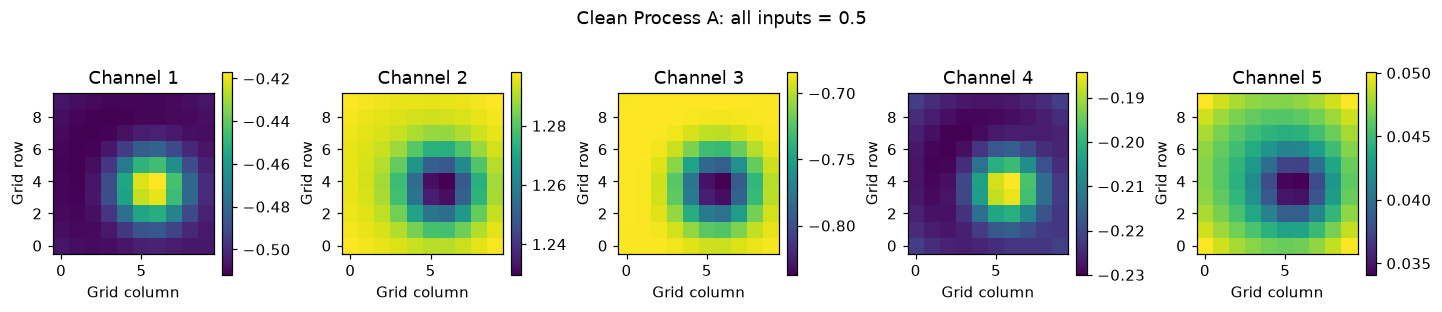

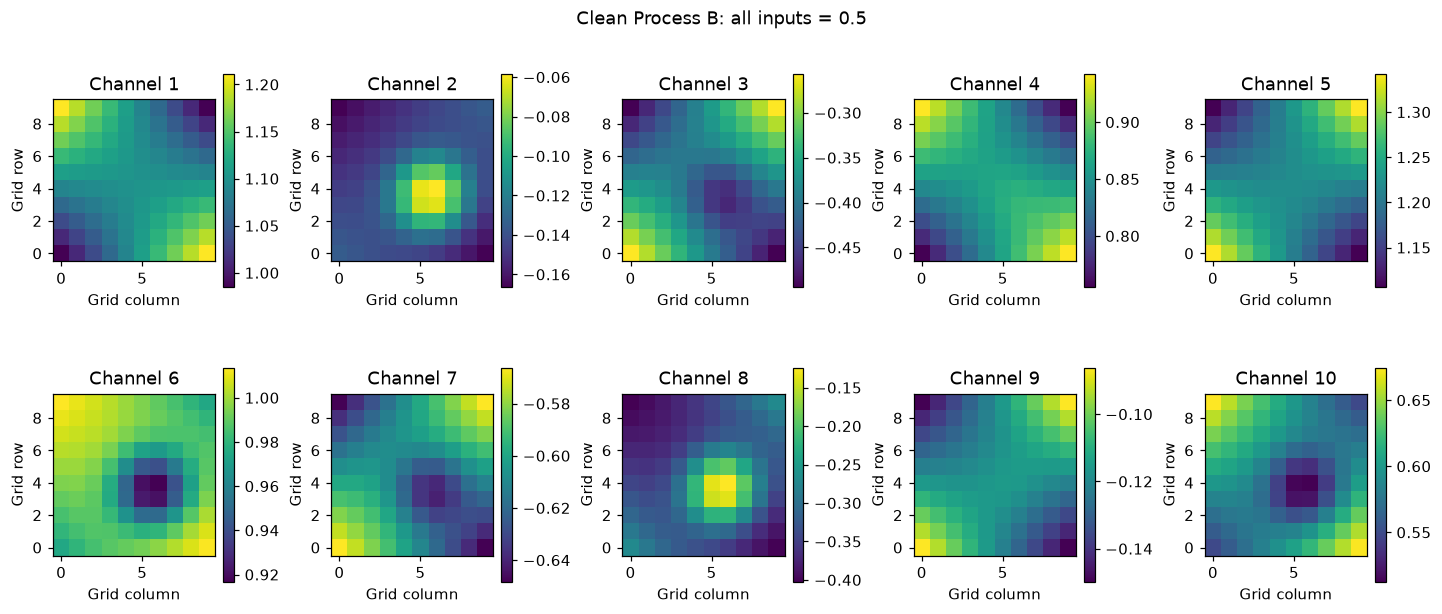

In [3]:
for process, config in CONFIG.items():
    input_setting = np.full((1, config["inputs"]), 0.5)
    maps = synthetic_function(input_setting, process)[0]
    rows = 1 if process == "A" else 2
    fig, axes = plt.subplots(rows, 5, figsize=(13, 2.8*rows), constrained_layout=True)
    for channel, ax in enumerate(np.asarray(axes).ravel()):
        im = ax.imshow(maps[:, :, channel], origin="lower", cmap="viridis")
        ax.set_title(f"Channel {channel+1}")
        ax.set(xlabel="Grid column", ylabel="Grid row")
        fig.colorbar(im, ax=ax, shrink=0.75)
    fig.suptitle(f"Clean Process {process}: all inputs = 0.5")
    save_plot(f"function_maps_{process}.png")


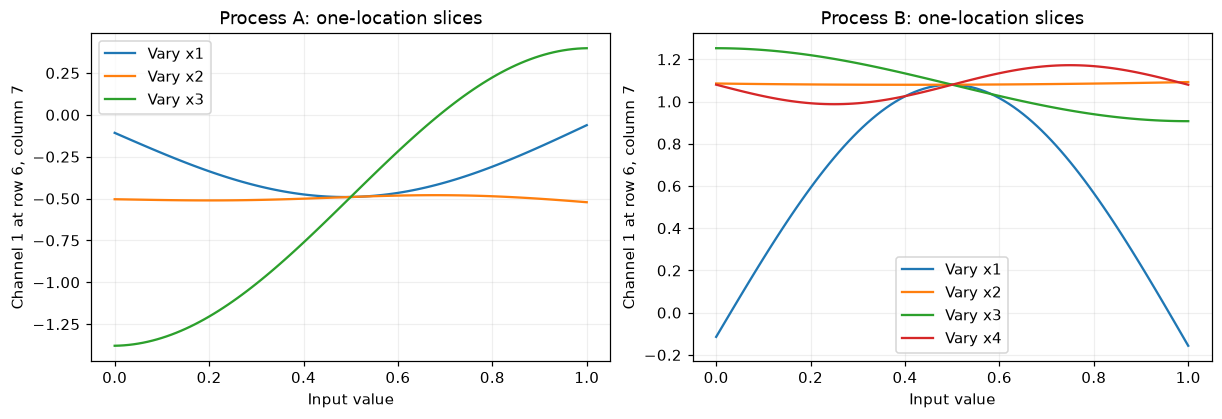

In [4]:
values = np.linspace(0, 1, 101)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7), constrained_layout=True)
for ax, (process, config) in zip(axes, CONFIG.items()):
    for j in range(config["inputs"]):
        input_settings = np.full((len(values), config["inputs"]), 0.5)
        input_settings[:, j] = values
        response = synthetic_function(input_settings, process)[:, 6, 7, 0]
        ax.plot(values, response, label=f"Vary x{j+1}")
    ax.set(title=f"Process {process}: one-location slices", xlabel="Input value",
           ylabel="Channel 1 at row 6, column 7")
    ax.legend(); ax.grid(alpha=0.2)
save_plot("function_input_slices.png")


In [5]:
SIZES = [20, 40, 80, 160]
SEEDS = [10, 20, 30, 40, 50]
N_TEST = 120
K = 5
MODEL_NAMES = ["PCA+GP", "PCA+RF", "PCA+MLP"]

def rmse(truth, prediction):
    return float(np.sqrt(np.mean((truth - prediction)**2)))

def new_gp(n_inputs, observation_noise=True):
    kernel = ConstantKernel(1.0, (0.05, 30.0)) * Matern(
        length_scale=np.ones(n_inputs), length_scale_bounds=(0.1, 10.0), nu=2.5)
    if observation_noise:
        kernel += WhiteKernel(0.01, (1e-6, 0.2))
    return GaussianProcessRegressor(kernel=kernel, alpha=1e-8,
                                    normalize_y=True, n_restarts_optimizer=0)

def prepare_data(X_train, Y_train, X_test):
    channels = Y_train.shape[-1]
    x_scale = StandardScaler().fit(X_train)
    y_scale = StandardScaler().fit(Y_train.reshape(-1, channels))
    Y_scaled = y_scale.transform(Y_train.reshape(-1, channels)).reshape(len(Y_train), -1)
    pca = PCA(n_components=K, svd_solver="full").fit(Y_scaled)
    Z = pca.transform(Y_scaled)
    z_scale = StandardScaler().fit(Z)
    return x_scale.transform(X_train), x_scale.transform(X_test), z_scale.transform(Z), y_scale, pca, z_scale

def decode(Z_scaled, y_scale, pca, z_scale, channels):
    Z = z_scale.inverse_transform(Z_scaled)
    Y_scaled = pca.inverse_transform(Z).reshape(-1, channels)
    return y_scale.inverse_transform(Y_scaled).reshape(-1, SIDE, SIDE, channels)


In [6]:
rows = []
diagnostics = []
examples = {}
started = perf_counter()

for process, config in CONFIG.items():
    for seed in SEEDS:
        rng = np.random.default_rng(seed + config["seed"])
        X_pool = rng.uniform(0, 1, (max(SIZES), config["inputs"]))
        X_test = rng.uniform(0, 1, (N_TEST, config["inputs"]))
        Y_pool_clean = synthetic_function(X_pool, process)
        Y_test_clean = synthetic_function(X_test, process)
        Y_pool = Y_pool_clean + rng.normal(0, NOISE, Y_pool_clean.shape)
        Y_test = Y_test_clean + rng.normal(0, NOISE, Y_test_clean.shape)
        channels = config["channels"]
        for n in SIZES:
            X_train, Y_train = X_pool[:n], Y_pool[:n]
            t0 = perf_counter()
            Xt, Xq, Zt, ys, pca, zs = prepare_data(X_train, Y_train, X_test)
            prep_seconds = perf_counter() - t0
            test_flat = ys.transform(Y_test.reshape(-1, channels)).reshape(N_TEST, -1)
            Z_test = zs.transform(pca.transform(test_flat))
            reconstructed = decode(Z_test, ys, pca, zs, channels)
            mean_prediction = np.broadcast_to(Y_train.mean(axis=0), Y_test_clean.shape)
            diagnostic = {"process": process, "seed": seed, "n_train": n,
                "pca_variance": pca.explained_variance_ratio_.sum(),
                "pca_oracle_rmse": rmse(Y_test_clean, reconstructed),
                "mean_map_rmse": rmse(Y_test_clean, mean_prediction)}
            predictions = {}
            for name in MODEL_NAMES:
                label = f"{process}/{seed}/{n}/{name}"
                t0 = perf_counter()
                if name == "PCA+GP":
                    models = []
                    for j in range(K):
                        gp = new_gp(config["inputs"])
                        models.append(fit_recorded(gp, Xt, Zt[:, j], label + f"/{j}"))
                elif name == "PCA+RF":
                    model = RandomForestRegressor(n_estimators=200, min_samples_leaf=1,
                                                  random_state=seed, n_jobs=1)
                    fit_recorded(model, Xt, Zt, label)
                else:
                    model = MLPRegressor(hidden_layer_sizes=(32,), activation="tanh",
                        solver="adam", alpha=0.1, learning_rate_init=0.01,
                        max_iter=3000, tol=1e-5, n_iter_no_change=30,
                        random_state=seed)
                    fit_recorded(model, Xt, Zt, label)
                fit_seconds = perf_counter() - t0
                t0 = perf_counter()
                if name == "PCA+GP":
                    result = [gp.predict(Xq, return_std=True) for gp in models]
                    Z_pred = np.column_stack([r[0] for r in result])
                    Z_std = np.column_stack([r[1] for r in result])
                    diagnostic["latent_95_coverage"] = np.mean(np.abs(Z_test - Z_pred) <= 1.96 * Z_std)
                    diagnostic["latent_95_width"] = np.mean(3.92 * Z_std)
                else:
                    Z_pred = model.predict(Xq)
                prediction = decode(Z_pred, ys, pca, zs, channels)
                predict_seconds = perf_counter() - t0
                predictions[name] = prediction[0]
                rows.append({"process": process, "seed": seed, "n_train": n, "model": name,
                    "rmse_clean": rmse(Y_test_clean, prediction),
                    "rmse_noisy": rmse(Y_test, prediction), "fit_seconds": fit_seconds,
                    "preprocess_seconds": prep_seconds, "predict_seconds": predict_seconds})
            diagnostics.append(diagnostic)

            if seed == SEEDS[0] and n == 80:
                examples[process] = {"truth": Y_test_clean[0], "predictions": predictions,
                    "pca_variance": np.cumsum(pca.explained_variance_ratio_)}
    print(f"Process {process} finished")

benchmark = pd.DataFrame(rows)
diagnostic_table = pd.DataFrame(diagnostics)
summary = benchmark.groupby(["process", "n_train", "model"]).agg(
    rmse_mean=("rmse_clean", "mean"), rmse_sd=("rmse_clean", "std"),
    noisy_rmse_mean=("rmse_noisy", "mean"), fit_seconds_mean=("fit_seconds", "mean")).reset_index()
print(f"Experiment 1 elapsed: {perf_counter() - started:.1f} seconds")
display(summary.round(5))


Process A finished
Process B finished
Experiment 1 elapsed: 15.7 seconds


,process,n_train,model,rmse_mean,rmse_sd,noisy_rmse_mean,fit_seconds_mean
0,A,20,PCA+GP,0.03583,0.00278,0.05006,0.05918
1,A,20,PCA+MLP,0.07644,0.01710,0.08424,0.10153
2,A,20,PCA+RF,0.23891,0.02166,0.24139,0.10818
3,A,40,PCA+GP,0.02034,0.00252,0.04053,0.05977
4,A,40,PCA+MLP,0.03447,0.00486,0.04916,0.11356
5,A,40,PCA+RF,0.17895,0.00854,0.18229,0.11126
6,A,80,PCA+GP,0.01200,0.00124,0.03700,0.09166
7,A,80,PCA+MLP,0.02517,0.00758,0.04340,0.10881
8,A,80,PCA+RF,0.14152,0.01226,0.14581,0.11946
9,A,160,PCA+GP,0.00785,0.00054,0.03584,0.26143


At 20 training input settings:
Process A: lowest mean RMSE at n=20 is PCA+GP.
Process B: lowest mean RMSE at n=20 is PCA+GP.


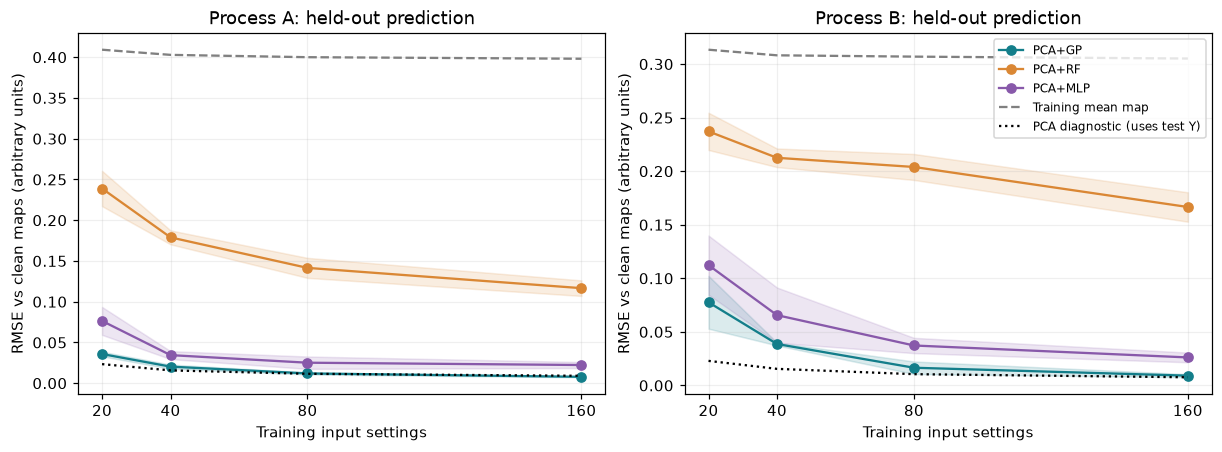

model,PCA+GP,PCA+MLP,PCA+RF
process,,,
A,0.03583,0.07644,0.23891
B,0.07763,0.11228,0.23718


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
colors = {"PCA+GP": "#137e8a", "PCA+RF": "#da8734", "PCA+MLP": "#8859aa"}
for ax, process in zip(axes, CONFIG):
    for name in MODEL_NAMES:
        part = summary[(summary.process == process) & (summary.model == name)]
        x = part.n_train.to_numpy()
        mean, sd = part.rmse_mean.to_numpy(), part.rmse_sd.to_numpy()
        ax.plot(x, mean, "o-", label=name, color=colors[name])
        ax.fill_between(x, np.maximum(0, mean-sd), mean+sd, alpha=.15, color=colors[name])
    base = diagnostic_table[diagnostic_table.process == process].groupby("n_train").mean(numeric_only=True)
    ax.plot(base.index, base.mean_map_rmse, "--", color="gray", label="Training mean map")
    ax.plot(base.index, base.pca_oracle_rmse, ":", color="black", label="PCA diagnostic (uses test Y)")
    ax.set(title=f"Process {process}: held-out prediction", xlabel="Training input settings",
           ylabel="RMSE vs clean maps (arbitrary units)", xticks=SIZES)
    ax.grid(alpha=.2)
axes[1].legend(fontsize=8)
save_plot("learning_curves.png")

small = summary[summary.n_train == 20].pivot(index="process", columns="model", values="rmse_mean")
print("At 20 training input settings:")
display(small.round(5))
for process in CONFIG:
    print(f"Process {process}: lowest mean RMSE at n=20 is {small.loc[process].idxmin()}.")


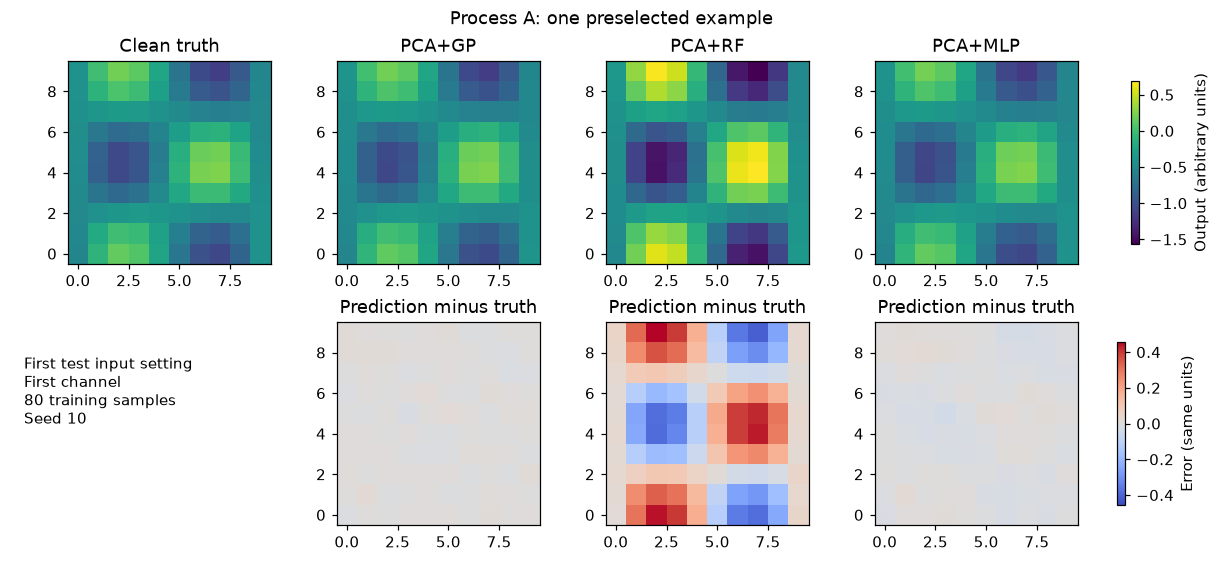

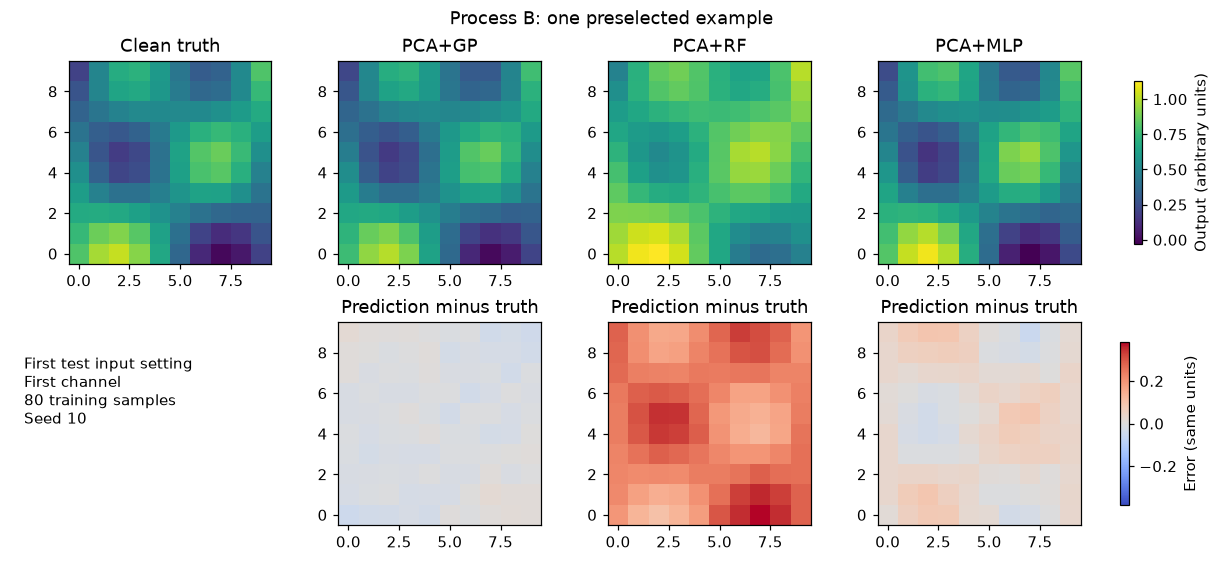

In [8]:
for process in CONFIG:
    example = examples[process]
    maps = [example["truth"][:, :, 0]] + [example["predictions"][name][:, :, 0] for name in MODEL_NAMES]
    lo, hi = min(m.min() for m in maps), max(m.max() for m in maps)
    error_max = max(np.abs(m - maps[0]).max() for m in maps[1:])
    fig, axes = plt.subplots(2, 4, figsize=(11, 5), constrained_layout=True)
    for j, (title, field) in enumerate(zip(["Clean truth"] + MODEL_NAMES, maps)):
        im = axes[0, j].imshow(field, origin="lower", vmin=lo, vmax=hi, cmap="viridis")
        axes[0, j].set_title(title)
        if j == 0:
            axes[1, j].axis("off")
            axes[1, j].text(.05, .5, "First test input setting\nFirst channel\n80 training samples\nSeed 10", transform=axes[1, j].transAxes)
        else:
            err = axes[1, j].imshow(field-maps[0], origin="lower", cmap="coolwarm", vmin=-error_max, vmax=error_max)
            axes[1, j].set_title("Prediction minus truth")
    fig.colorbar(im, ax=axes[0, :], shrink=.8, label="Output (arbitrary units)")
    fig.colorbar(err, ax=axes[1, 1:], shrink=.8, label="Error (same units)")
    fig.suptitle(f"Process {process}: one preselected example")
    save_plot(f"maps_{process}.png")


,process,n_train,pca_variance,pca_oracle_rmse,mean_map_rmse,latent_95_coverage,latent_95_width
0,A,20,0.98045,0.02342,0.40922,0.88467,0.95677
1,A,40,0.97800,0.01574,0.40289,0.92267,0.58051
2,A,80,0.97619,0.01157,0.40004,0.94333,0.41367
3,A,160,0.97526,0.00910,0.39813,0.95267,0.35544
4,B,20,0.98161,0.02293,0.31342,0.93067,1.20050
5,B,40,0.97735,0.01548,0.30818,0.92967,0.60926
6,B,80,0.97462,0.01052,0.30696,0.96300,0.27982
7,B,160,0.97413,0.00763,0.30518,0.94733,0.17127


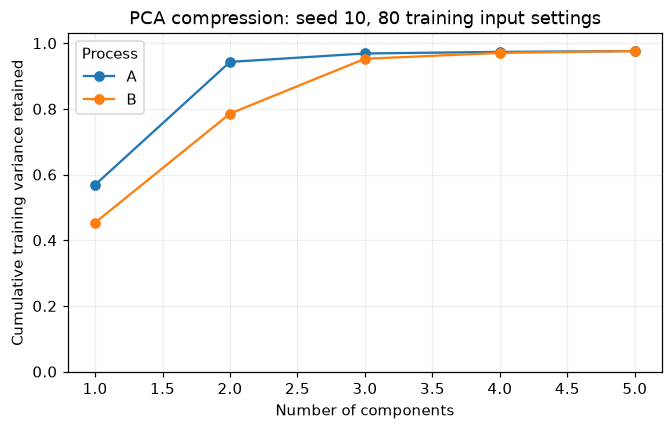

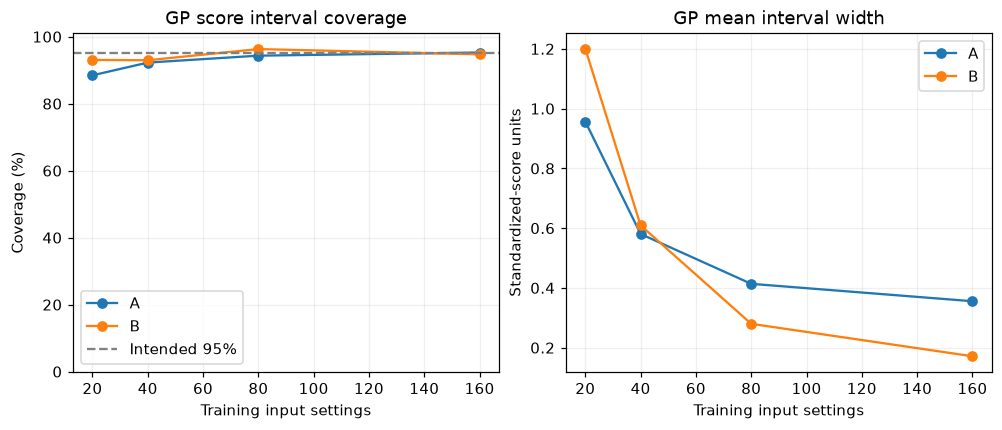

In [9]:
diag_summary = diagnostic_table.groupby(["process", "n_train"]).mean(numeric_only=True).reset_index()
display(diag_summary.drop(columns="seed").round(5))

fig, ax = plt.subplots(figsize=(6, 3.8), constrained_layout=True)
for process in CONFIG:
    ax.plot(range(1, K+1), examples[process]["pca_variance"], "o-", label=process)
ax.set(title="PCA compression: seed 10, 80 training input settings", xlabel="Number of components",
       ylabel="Cumulative training variance retained", ylim=(0, 1.03))
ax.legend(title="Process")
ax.grid(alpha=.2)
save_plot("pca_compression.png")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), constrained_layout=True)
for process in CONFIG:
    part = diag_summary[diag_summary.process == process]
    axes[0].plot(part.n_train, 100*part.latent_95_coverage, "o-", label=process)
    axes[1].plot(part.n_train, part.latent_95_width, "o-", label=process)
axes[0].axhline(95, color="gray", linestyle="--", label="Intended 95%")
axes[0].set(title="GP score interval coverage", xlabel="Training input settings", ylabel="Coverage (%)", ylim=(0, 101))
axes[1].set(title="GP mean interval width", xlabel="Training input settings", ylabel="Standardized-score units")
for ax in axes:
    ax.legend()
    ax.grid(alpha=.2)
save_plot("gp_uncertainty.png")


In [10]:
PCA_BO_SEEDS = SEEDS
PCA_BO_INITIAL = 20
PCA_BO_STEPS = 24
PCA_BO_CANDIDATES = 1500
PCA_BO_DRAWS = 128
PCA_BO_TARGETS = {"A": np.array([[0.35, 0.65, 0.45]]),
                  "B": np.array([[0.35, 0.65, 0.45, 0.55]])}
pca_bo_targets = {p: synthetic_function(x, p)[0] for p, x in PCA_BO_TARGETS.items()}

def map_mse(maps, target):
    return np.mean((maps - target)**2, axis=(1, 2, 3))

def map_loss_geometry(ys, pca, zs, channels, target):
    origin = decode(np.zeros((1, K)), ys, pca, zs, channels)[0].ravel()
    directions = decode(np.eye(K), ys, pca, zs, channels).reshape(K, -1) - origin
    residual = origin - target.ravel()
    return directions @ directions.T / len(origin), directions @ residual / len(origin), np.mean(residual**2)

def sampled_map_losses(scores, metric, linear, constant):
    return np.maximum(0, constant + 2 * (scores @ linear)
                      + np.einsum("...i,ij,...j->...", scores, metric, scores))

pca_bo_rows = []
pca_bo_trials = []
pca_bo_choices = []
pca_bo_warning_start = len(warning_log)
pca_bo_started = perf_counter()
for process, config in CONFIG.items():
    candidates = np.random.default_rng(7000 + config["seed"]).uniform(
        0, 1, (PCA_BO_CANDIDATES, config["inputs"]))
    target = pca_bo_targets[process]
    for seed in PCA_BO_SEEDS:
        rng = np.random.default_rng(seed + config["seed"])
        X_pool = rng.uniform(0, 1, (160, config["inputs"]))
        X_test_unused = rng.uniform(0, 1, (120, config["inputs"]))
        clean_pool = synthetic_function(X_pool, process)
        noisy_pool = clean_pool + rng.normal(0, NOISE, clean_pool.shape)
        X_initial = X_pool[:PCA_BO_INITIAL]
        Y_initial = noisy_pool[:PCA_BO_INITIAL]
        ys = StandardScaler().fit(Y_initial.reshape(-1, config["channels"]))
        flat = ys.transform(Y_initial.reshape(-1, config["channels"])).reshape(PCA_BO_INITIAL, -1)
        pca = PCA(n_components=K, svd_solver="full").fit(flat)
        zs = StandardScaler().fit(pca.transform(flat))
        xs = StandardScaler().fit(X_initial)
        metric, linear, constant = map_loss_geometry(ys, pca, zs, config["channels"], target)
        check_scores = np.random.default_rng(seed).normal(size=(3, K))
        np.testing.assert_allclose(sampled_map_losses(check_scores, metric, linear, constant),
            map_mse(decode(check_scores, ys, pca, zs, config["channels"]), target), atol=1e-12)
        _, _, original_scores, original_ys, original_pca, original_zs = prepare_data(
            X_initial, Y_initial, candidates[:1])
        np.testing.assert_allclose(zs.transform(pca.transform(flat)), original_scores, atol=1e-12)
        for method in ["PCA+GP BO", "Random search"]:
            X_seen = X_initial.copy()
            Y_seen = Y_initial.copy()
            observed = map_mse(Y_seen, target).tolist()
            clean_values = map_mse(clean_pool[:PCA_BO_INITIAL], target).tolist()
            chosen = []
            noise_rng = np.random.default_rng(23000 + seed + config["seed"])
            acquisition_rng = np.random.default_rng(33000 + seed + config["seed"])
            order = np.random.default_rng(43000 + seed).permutation(PCA_BO_CANDIDATES)
            for i in range(PCA_BO_INITIAL):
                row = {"process": process, "seed": seed, "method": method,
                    "evaluation": i+1, "candidate_id": -1, "observed_mse": observed[i],
                    "clean_mse": clean_values[i], "initial": True}
                row.update({f"x{j+1}": X_seen[i,j] for j in range(config["inputs"])})
                pca_bo_trials.append(row)
            pca_bo_rows.append({"process": process, "seed": seed, "method": method,
                "evaluations": PCA_BO_INITIAL, "best_observed_mse": min(observed),
                "best_clean_mse": min(clean_values), "recommended_clean_mse": clean_values[int(np.argmin(observed))]})
            for step in range(PCA_BO_STEPS):
                if method == "PCA+GP BO":
                    Z_seen = zs.transform(pca.transform(ys.transform(
                        Y_seen.reshape(-1, config["channels"])).reshape(len(Y_seen), -1)))
                    means, deviations = [], []
                    for j in range(K):
                        gp = new_gp(config["inputs"])
                        fit_recorded(gp, xs.transform(X_seen), Z_seen[:, j],
                            f"PCA_BO/{process}/{seed}/{step}/{j}")
                        mean, deviation = gp.predict(xs.transform(candidates), return_std=True)
                        means.append(mean)
                        deviations.append(deviation)
                    means = np.column_stack(means)
                    deviations = np.column_stack(deviations)
                    normal_draws = acquisition_rng.normal(size=(PCA_BO_DRAWS, 1, K))
                    possible_scores = means[None, :, :] + deviations[None, :, :] * normal_draws
                    possible_losses = sampled_map_losses(possible_scores, metric, linear, constant)
                    improvement = np.maximum(min(observed) - possible_losses, 0)
                    acquisition = improvement.mean(axis=0)
                    acquisition[chosen] = -np.inf
                    if np.max(acquisition) > 0:
                        next_id = int(np.argmax(acquisition))
                    else:
                        predicted_loss = sampled_map_losses(means, metric, linear, constant)
                        predicted_loss[chosen] = np.inf
                        next_id = int(np.argmin(predicted_loss))
                    pca_bo_choices.append({"process": process, "seed": seed, "step": step+1,
                        "candidate_id": next_id, "estimated_ei": acquisition[next_id],
                        "best_observed_before": min(observed)})
                else:
                    next_id = int(order[step])
                clean_map = synthetic_function(candidates[[next_id]], process)
                noisy_map = clean_map + noise_rng.normal(0, NOISE, clean_map.shape)
                actual_observed = float(map_mse(noisy_map, target)[0])
                actual_clean = float(map_mse(clean_map, target)[0])
                chosen.append(next_id)
                X_seen = np.vstack([X_seen, candidates[[next_id]]])
                Y_seen = np.concatenate([Y_seen, noisy_map])
                observed.append(actual_observed)
                clean_values.append(actual_clean)
                row = {"process": process, "seed": seed, "method": method,
                    "evaluation": len(observed), "candidate_id": next_id,
                    "observed_mse": actual_observed, "clean_mse": actual_clean, "initial": False}
                row.update({f"x{j+1}": candidates[next_id,j] for j in range(config["inputs"])})
                pca_bo_trials.append(row)
                pca_bo_rows.append({"process": process, "seed": seed, "method": method,
                    "evaluations": len(observed), "best_observed_mse": min(observed),
                    "best_clean_mse": min(clean_values),
                    "recommended_clean_mse": clean_values[int(np.argmin(observed))]})
            assert len(chosen) == len(set(chosen)) == PCA_BO_STEPS
        print(f"PCA+GP BO: process {process}, seed {seed} finished", flush=True)

pca_bo_history = pd.DataFrame(pca_bo_rows)
pca_bo_evaluations = pd.DataFrame(pca_bo_trials)
pca_bo_final = pca_bo_history[pca_bo_history.evaluations == PCA_BO_INITIAL + PCA_BO_STEPS]
pca_bo_summary = pca_bo_final.groupby(["process", "method"]).agg(
    recommended_clean_mse_mean=("recommended_clean_mse", "mean"),
    recommended_clean_mse_sd=("recommended_clean_mse", "std"),
    best_clean_mse_mean=("best_clean_mse", "mean"),
    best_observed_mse_mean=("best_observed_mse", "mean")).reset_index()
print(f"Experiment 2 elapsed: {perf_counter() - pca_bo_started:.1f} seconds")
display(pca_bo_summary)


PCA+GP BO: process A, seed 10 finished
PCA+GP BO: process A, seed 20 finished
PCA+GP BO: process A, seed 30 finished
PCA+GP BO: process A, seed 40 finished
PCA+GP BO: process A, seed 50 finished
PCA+GP BO: process B, seed 10 finished
PCA+GP BO: process B, seed 20 finished
PCA+GP BO: process B, seed 30 finished
PCA+GP BO: process B, seed 40 finished
PCA+GP BO: process B, seed 50 finished
Experiment 2 elapsed: 20.2 seconds


,process,method,recommended_clean_mse_mean,recommended_clean_mse_sd,best_clean_mse_mean,best_observed_mse_mean
0,A,PCA+GP BO,0.000616,9.023635e-07,0.000616,0.001790
1,A,Random search,0.006401,5.026060e-03,0.006305,0.007579
2,B,PCA+GP BO,0.002047,0.000000e+00,0.002047,0.003213
3,B,Random search,0.009616,2.684623e-03,0.009616,0.010916


Process A: PCA+GP BO wins 5/5 paired runs.
Process B: PCA+GP BO wins 5/5 paired runs.


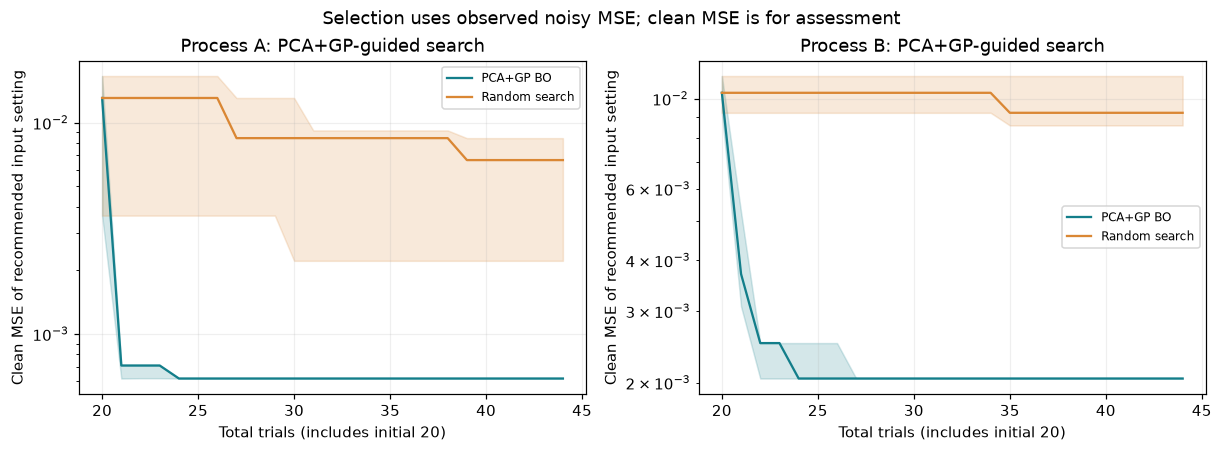

method        PCA+GP BO  Random search
process seed                          
A       10     0.000616       0.002220
        20     0.000616       0.013567
        30     0.000616       0.006653
        40     0.000618       0.001115
        50     0.000616       0.008451
B       10     0.002047       0.012947
        20     0.002047       0.011367
        30     0.002047       0.009229
        40     0.002047       0.008592
        50     0.002047       0.005946

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for ax, process in zip(axes, CONFIG):
    for method, color in [("PCA+GP BO", "#137e8a"), ("Random search", "#da8734")]:
        part = pca_bo_history[(pca_bo_history.process == process) & (pca_bo_history.method == method)]
        grouped = part.groupby("evaluations").recommended_clean_mse
        median = grouped.median()
        ax.plot(median.index, median, label=method, color=color)
        ax.fill_between(median.index, grouped.quantile(.25), grouped.quantile(.75), alpha=.18, color=color)
    ax.set(title=f"Process {process}: PCA+GP-guided search", xlabel="Total trials (includes initial 20)",
           ylabel="Clean MSE of recommended input setting", yscale="log")
    ax.grid(alpha=.2)
    ax.legend(fontsize=8)
fig.suptitle("Selection uses observed noisy MSE; clean MSE is for assessment")
save_plot("pca_bo_curves.png")
pca_bo_paired = pca_bo_final.pivot(index=["process", "seed"], columns="method", values="recommended_clean_mse")
for process in CONFIG:
    part = pca_bo_paired.loc[process]
    wins = int((part["PCA+GP BO"] < part["Random search"] - 1e-12).sum())
    print(f"Process {process}: PCA+GP BO wins {wins}/{len(PCA_BO_SEEDS)} paired runs.")
display(pca_bo_paired)


In [12]:
assert len(pca_bo_history) == 2 * len(PCA_BO_SEEDS) * 2 * (PCA_BO_STEPS + 1)
assert np.isfinite(pca_bo_evaluations[["observed_mse", "clean_mse"]]).all().all()
for process, config in CONFIG.items():
    inputs = [f"x{j+1}" for j in range(config["inputs"])]
    assert np.isfinite(pca_bo_evaluations.loc[pca_bo_evaluations.process == process, inputs]).all().all()
for _, group in pca_bo_history.groupby(["process", "seed", "method"]):
    assert (np.diff(group.best_observed_mse) <= 1e-12).all()
for _, group in pca_bo_evaluations.groupby(["process", "seed"]):
    a = group[(group.method == "PCA+GP BO") & group.initial]
    b = group[(group.method == "Random search") & group.initial]
    np.testing.assert_array_equal(a.observed_mse, b.observed_mse)
    np.testing.assert_array_equal(a.clean_mse, b.clean_mse)
    for _, method_group in group.groupby("method"):
        assert len(method_group) == PCA_BO_INITIAL + PCA_BO_STEPS
pca_bo_warnings = pd.DataFrame(warning_log[pca_bo_warning_start:], columns=["fit", "type", "message"])
print("Checked map-loss arithmetic, Experiment 1 initialization, equal starts, trial counts, finite values and best-observed traces.")
print("PCA+GP BO warnings:", len(pca_bo_warnings))


Checked map-loss arithmetic, Experiment 1 initialization, equal starts, trial counts, finite values and best-observed traces.
PCA+GP BO warnings: 1849


In [13]:
from sklearn.pipeline import make_pipeline

OUTPUT_IDS = [f"A-{j+1}" for j in range(5)] + [f"B-{j+1}" for j in range(10)]
locations = np.column_stack([grid_x.ravel(), grid_y.ravel()])
training_axis = [0, 2, 4, 6, 9]
training_points = np.array([r*SIDE+c for r in training_axis for c in training_axis])

def make_queries(X, process, points):
    channels = CONFIG[process]["channels"]
    values = np.zeros((len(X), 4))
    values[:, :X.shape[1]] = X
    mask = np.zeros((len(X), 4))
    mask[:, :X.shape[1]] = 1
    input_settings = np.repeat(np.column_stack([values, mask]), len(points)*channels, axis=0)
    positions = np.tile(np.repeat(locations[points], channels, axis=0), (len(X), 1))
    first_id = 0 if process == "A" else 5
    channel_flags = np.eye(15)[first_id:first_id+channels]
    ids = np.tile(channel_flags, (len(X)*len(points), 1))
    return np.column_stack([input_settings, positions, ids])

example_query = make_queries(np.array([[0.2, 0.6, 0.8]]), "A", np.array([67]))
print("Query shape:", example_query.shape, "= five channel questions, 25 features each")
print("First query (A-1):", example_query[0])
print("Output IDs:", OUTPUT_IDS)


Query shape: (5, 25) = five channel questions, 25 features each
First query (A-1): [0.2        0.6        0.8        0.         1.         1.
 1.         0.         0.55555556 0.33333333 1.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.        ]
Output IDs: ['A-1', 'A-2', 'A-3', 'A-4', 'A-5', 'B-1', 'B-2', 'B-3', 'B-4', 'B-5', 'B-6', 'B-7', 'B-8', 'B-9', 'B-10']


In [14]:
SHARED_SEEDS = [101, 202, 303]
shared_rows = []
shared_examples = {}
shared_warning_start = len(warning_log)

for seed in SHARED_SEEDS:
    prepared = {}
    for process, config in CONFIG.items():
        rng = np.random.default_rng(seed + config["seed"])
        X_train = rng.uniform(0, 1, (40, config["inputs"]))
        X_test = rng.uniform(0, 1, (60, config["inputs"]))
        clean_train = synthetic_function(X_train, process).reshape(40, 100, -1)
        clean_test = synthetic_function(X_test, process).reshape(60, 100, -1)
        observed = clean_train[:, training_points, :]
        observed = observed + rng.normal(0, NOISE, observed.shape)
        channels = config["channels"]
        output_scale = StandardScaler().fit(observed.reshape(-1, channels))
        targets = output_scale.transform(observed.reshape(-1, channels)).ravel()
        prepared[process] = {
            "train": make_queries(X_train, process, training_points),
            "test": make_queries(X_test, process, np.arange(100)),
            "targets": targets, "truth": clean_test, "scale": output_scale}

    all_queries = np.vstack([prepared[p]["train"] for p in CONFIG])
    all_targets = np.concatenate([prepared[p]["targets"] for p in CONFIG])
    shared_model = make_pipeline(StandardScaler(), MLPRegressor(
        hidden_layer_sizes=(64, 32), activation="tanh", solver="adam",
        alpha=0.01, learning_rate_init=0.003, batch_size=256,
        max_iter=1000, tol=1e-5, n_iter_no_change=25, random_state=seed))
    fit_recorded(shared_model, all_queries, all_targets, f"shared/{seed}/pooled")

    for process, data in prepared.items():
        separate_model = make_pipeline(StandardScaler(), MLPRegressor(
            hidden_layer_sizes=(64, 32), activation="tanh", solver="adam",
            alpha=0.01, learning_rate_init=0.003, batch_size=256,
            max_iter=1000, tol=1e-5, n_iter_no_change=25, random_state=seed))
        fit_recorded(separate_model, data["train"], data["targets"], f"shared/{seed}/{process}/separate")
        channels = CONFIG[process]["channels"]
        for name, model in [("Shared scalar", shared_model), ("Separate scalar", separate_model)]:
            normalized = model.predict(data["test"]).reshape(-1, channels)
            predicted = data["scale"].inverse_transform(normalized).reshape(60, 100, channels)
            shared_rows.append({"process": process, "seed": seed, "model": name,
                                "rmse": rmse(data["truth"], predicted)})
            if seed == SHARED_SEEDS[0]:
                shared_examples[(process, name)] = predicted[0, :, 0].reshape(10, 10)
                shared_examples[(process, "Truth")] = data["truth"][0, :, 0].reshape(10, 10)
    print(f"Shared-output comparison finished for seed {seed}")

shared_results = pd.DataFrame(shared_rows)
shared_summary = shared_results.groupby(["process", "model"]).rmse.agg(["mean", "std"]).reset_index()
shared_warnings = pd.DataFrame(warning_log[shared_warning_start:], columns=["fit", "type", "message"])
display(shared_summary.round(5))
print("Shared experiment optimizer warnings:", len(shared_warnings))
if len(shared_warnings):
    display(shared_warnings)


Shared-output comparison finished for seed 101
Shared-output comparison finished for seed 202
Shared-output comparison finished for seed 303
Shared experiment optimizer warnings: 0


,process,model,mean,std
0,A,Separate scalar,0.14225,0.00674
1,A,Shared scalar,0.13662,0.00698
2,B,Separate scalar,0.11187,0.02216
3,B,Shared scalar,0.10663,0.00901


A: shared wins 3/3 paired splits; mean RMSE change -4.0% (negative is better).
B: shared wins 2/3 paired splits; mean RMSE change -4.7% (negative is better).
Shared-result count, finite errors, and training-query sizes checked.


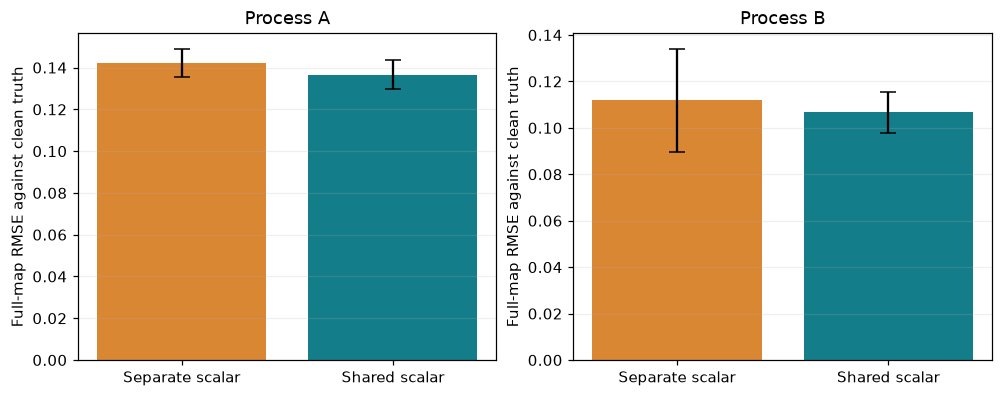

model         Separate scalar  Shared scalar
process seed                                
A       101           0.14729        0.14465
        202           0.14486        0.13327
        303           0.13459        0.13194
B       101           0.13485        0.11627
        202           0.11015        0.10522
        303           0.09062        0.09842

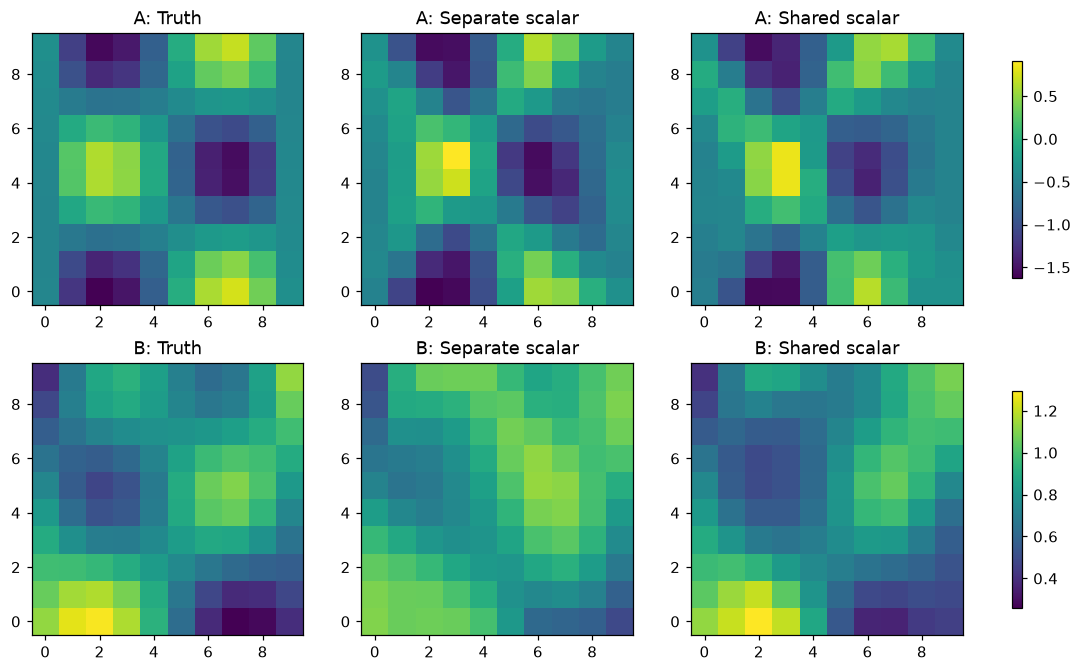

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), constrained_layout=True)
for ax, process in zip(axes, CONFIG):
    part = shared_summary[shared_summary.process == process]
    ax.bar(part.model, part["mean"], yerr=part["std"], capsize=5, color=["#da8734", "#137e8a"])
    ax.set(title=f"Process {process}", ylabel="Full-map RMSE against clean truth")
    ax.grid(axis="y", alpha=0.2)
save_plot("shared_query_comparison.png")

paired_shared = shared_results.pivot(index=["process", "seed"], columns="model", values="rmse")
display(paired_shared.round(5))
for process in CONFIG:
    part = paired_shared.loc[process]
    wins = (part["Shared scalar"] < part["Separate scalar"]).sum()
    change = 100*(part["Shared scalar"].mean()/part["Separate scalar"].mean()-1)
    print(f"{process}: shared wins {wins}/3 paired splits; mean RMSE change {change:+.1f}% (negative is better).")

fig, axes = plt.subplots(2, 3, figsize=(10, 6), constrained_layout=True)
for row, process in enumerate(CONFIG):
    fields = [shared_examples[(process, name)] for name in ["Truth", "Separate scalar", "Shared scalar"]]
    lo, hi = min(x.min() for x in fields), max(x.max() for x in fields)
    for ax, name, field in zip(axes[row], ["Truth", "Separate scalar", "Shared scalar"], fields):
        im = ax.imshow(field, origin="lower", vmin=lo, vmax=hi)
        ax.set_title(f"{process}: {name}")
    fig.colorbar(im, ax=axes[row].tolist(), shrink=0.8)
save_plot("shared_query_maps.png")
assert len(shared_results) == 12
assert np.isfinite(shared_results.rmse).all()
assert all(len(prepared[p]["train"]) == 40*25*CONFIG[p]["channels"] for p in CONFIG)
print("Shared-result count, finite errors, and training-query sizes checked.")
